# Reproduce the HTR2A/Htr2a motor-cortex pilot

Run these notebooks with the working directory set to the project's `notebooks/` directory. The saved pilot used the Allen ABC Atlas manifest `releases/20261031/manifest.json` and the cache at `../../data/abc_atlas`. Check the manifest printed by each notebook before generating inputs.

1. Run `01_inspect_narrow_mouse_data.ipynb` and `02_inspect_narrow_human_data.ipynb` to create the metadata CSVs in `../data/region_exports/`.
2. Run `03_compare_counts.ipynb` to export raw counts for mouse `Htr2a` (Macosko-10X-Isocortex) and human `HTR2A` (WHB-10Xv3-Neurons).
3. Run this notebook through the query export. It samples 50 GABA and 50 Glut cells per mouse from MOp with seed 490 and excludes `Htr2a` from `mouse_MOp_mapping_pilot.h5ad`.
4. Use the original mapping output at `../data/cell_mapping/hierarchical_mapping.csv` to reproduce the summaries and plot. For a fresh mapping run, recover the original mapping command or service settings, mapper version, reference name and release, and mapping parameters. Those details were absent from the supplied notebooks. Keep the mapping CSV with the configuration used to generate it.
5. Run the remaining cells. Each dot is one human donor or mouse, and the horizontal bars are medians of those rates. Detection means raw count greater than zero. The two output CSVs cover all four superclusters in the comparison, including the two plotted panels.

In [40]:
import numpy as np
import pandas as pd
import scipy
#import anndata as ad
# import scanpy as sc

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
# print("Scanpy:", sc.__version__)
print("All imports successful!")

NumPy: 2.5.5
Pandas: 3.1.1
SciPy: 1.18.1
All imports successful!


In [41]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
from abc_atlas_access.abc_atlas_cache.abc_project_cache import AbcProjectCache

In [43]:
download_base = Path('../../data/abc_atlas')
abc_cache = AbcProjectCache.from_cache_dir(download_base)

abc_cache.current_manifest

/home/lilyg/venvs/nrsc490/lib/python3.14/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:679: OutdatedManifestWarning: You are loading releases/20261031/manifest.json. A more up to date version of the dataset -- releases/20261130/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20261031/manifest.json', 'releases/20261130/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20261130/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


'releases/20261031/manifest.json'

In [44]:
import anndata as ad

In [45]:
import pandas as pd

export_dir = Path("../data/region_exports")

mouse = pd.read_csv(
    export_dir / "mouse_M1_S1_V1_metadata.csv",
    index_col="cell_label",
)

mouse_mop = mouse.loc[
    mouse["region_of_interest_acronym"].eq("MOp")
    & mouse["neurotransmitter"].isin(["GABA", "Glut"])
]

cells_per_group_target = 200
sampling_seed = 490

strata = mouse_mop.groupby(
    ["donor_label", "neurotransmitter"], sort=True, observed=True
)
available = strata.size().unstack(fill_value=0).reindex(
    columns=["GABA", "Glut"], fill_value=0
)

if available.shape != (12, 2) or available.eq(0).any().any():
    raise ValueError("Expected both neurotransmitter groups for all 12 mice.")

cells_per_group = min(cells_per_group_target, int(available.min().min()))
if cells_per_group <= 50:
    raise ValueError("The available balanced sample is no larger than the pilot.")

sampled = pd.concat([
    group.sample(n=cells_per_group, random_state=sampling_seed)
    for _, group in strata
])

print(f"Selected {len(sampled):,} cells ({cells_per_group} per mouse per group).")
display(sampled.groupby(["donor_label", "neurotransmitter"]).size().unstack())

if not sampled.index.is_unique:
    raise ValueError("Expected one metadata row per cell_label.")

display(
    sampled.groupby(["donor_label", "neurotransmitter"])
    .size()
    .unstack(fill_value=0)
)

mouse_directory = "Consensus-WMB-Macosko-10X"
mouse_raw_path = abc_cache.get_data_path(
    directory=mouse_directory,
    file_name="Macosko-10X-Isocortex/raw",
)

# Omit the gene you're testing from the expression profiles used for mapping.
mouse_genes = abc_cache.get_metadata_dataframe(
    directory=mouse_directory,
    file_name="gene",
)
htr2a_ids = mouse_genes.loc[
    mouse_genes["gene_symbol"].eq("Htr2a"), "gene_identifier"
].tolist()

source = ad.read_h5ad(mouse_raw_path, backed="r")
try:
    missing_ids = sampled.index.difference(source.obs_names)
    if len(missing_ids):
        raise ValueError(f"{len(missing_ids)} sampled cell IDs are missing from the matrix.")

    keep_rows = source.obs_names.isin(sampled.index)
    is_htr2a = source.var_names.isin(["Htr2a", *htr2a_ids])
    if is_htr2a.sum() != 1:
        raise ValueError("Expected exactly one Htr2a feature in the mouse matrix.")

    print(f"Reading {keep_rows.sum():,} sampled rows...", flush=True)
    sampled_query = source[keep_rows, :].to_memory()
    print(f"Loaded {sampled_query.shape}. Removing Htr2a...", flush=True)
    query = sampled_query[:, ~is_htr2a].copy()
    del sampled_query
finally:
    source.file.close()

query_path = export_dir / "mouse_MOp_mapping_larger.h5ad"
query.write_h5ad(query_path, compression="gzip")
print(f"Saved {query.n_obs:,} cells × {query.n_vars:,} genes to {query_path.resolve()}")

Selected 4,656 cells (194 per mouse per group).


neurotransmitter,GABA,Glut
donor_label,,
F003,194,194
F004,194,194
F005,194,194
F006,194,194
F007,194,194
F008,194,194
M002,194,194
M003,194,194
M004,194,194


neurotransmitter,GABA,Glut
donor_label,,
F003,194,194
F004,194,194
F005,194,194
F006,194,194
F007,194,194
F008,194,194
M002,194,194
M003,194,194
M004,194,194


Reading 4,656 sampled rows...
Loaded (4656, 21205). Removing Htr2a...
Saved 4,656 cells × 21,204 genes to /mnt/c/Users/lilyg/OneDrive/UPS/Fall 2026 UPS/NRSC 490/human-mouse-cortex/data/region_exports/mouse_MOp_mapping_larger.h5ad


In [46]:
mapping_path = Path("../data/cell_mapping/hierarchical_mapping_larger.csv")
if not mapping_path.is_file():
    raise FileNotFoundError(
        f"Missing {mapping_path}. Place the original mapping CSV there "
        "or regenerate it using the recorded mapping settings."
    )

mapping = pd.read_csv(
    mapping_path,
    comment="#",
    index_col="cell_id",
)

mouse_htr2a = pd.read_csv(
    export_dir / "mouse_M1_S1_V1_Htr2a_counts.csv",
    index_col="cell_label",
)

mapped_mouse = mapping.join(
    mouse_htr2a[["donor_label", "neurotransmitter", "raw_count"]],
    how="left",
    validate="one_to_one",
)

print("Mapping rows missing mouse metadata:", mapped_mouse["donor_label"].isna().sum())

display(pd.crosstab(
    mapped_mouse["supercluster_name"],
    mapped_mouse["neurotransmitter"],
))

display(
    mapped_mouse.groupby("supercluster_name")
    .agg(
        n_cells=("donor_label", "size"),
        n_mice=("donor_label", "nunique"),
        median_support=("supercluster_bootstrapping_probability", "median"),
    )
    .sort_values("n_cells", ascending=False)
    .round(2)
)

Mapping rows missing mouse metadata: 0


neurotransmitter,GABA,Glut
supercluster_name,,
Amygdala excitatory,0,31
CGE interneuron,601,0
Deep-layer corticothalamic and 6b,0,420
Deep-layer intratelencephalic,0,374
Deep-layer near-projecting,0,69
Eccentric medium spiny neuron,13,0
Hippocampal CA1-3,0,129
LAMP5-LHX6 and Chandelier,35,0
MGE interneuron,1501,0


,n_cells,n_mice,median_support
supercluster_name,,,
MGE interneuron,1501,12,1.00
Upper-layer intratelencephalic,1111,12,0.83
CGE interneuron,601,12,0.97
Deep-layer corticothalamic and 6b,420,12,0.96
Deep-layer intratelencephalic,374,12,0.66
Miscellaneous,199,12,0.57
Hippocampal CA1-3,129,12,0.78
Medium spiny neuron,105,2,0.99
Deep-layer near-projecting,69,12,0.80


In [47]:
human_htr2a = pd.read_csv(
    export_dir / "human_M1_S1_V1_HTR2A_counts.csv",
    index_col="cell_label",
)

In [48]:
superclusters = [
    "MGE interneuron",
    "CGE interneuron",
    "Upper-layer intratelencephalic",
    "Deep-layer corticothalamic and 6b",
]

human_m1 = human_htr2a.loc[
    human_htr2a["region"].eq("M1"),
    ["donor_label", "supercluster", "raw_count"],
].assign(species="Human")

mouse_mop = (
    mapped_mouse[["donor_label", "supercluster_name", "raw_count"]]
    .rename(columns={"supercluster_name": "supercluster"})
    .assign(species="Mouse")
)

comparison = pd.concat([human_m1, mouse_mop], ignore_index=True)
comparison = comparison.loc[
    comparison["supercluster"].isin(superclusters)
].dropna(subset=["raw_count"])

supercluster_detection = (
    comparison.assign(detected=comparison["raw_count"].gt(0))
    .groupby(["supercluster", "species", "donor_label"])
    .agg(
        n_cells=("raw_count", "size"),
        n_detected=("detected", "sum"),
    )
)

supercluster_detection["pct_detected"] = (
    100 * supercluster_detection["n_detected"] / supercluster_detection["n_cells"]
)

display(supercluster_detection.round(2))

n_cells  n_detected  \
supercluster                   species donor_label                        
CGE interneuron                Human   H18.30.001      4352         363   
                                       H18.30.002      4012         500   
                                       H19.30.001      1736         119   
                                       H19.30.002      1878         173   
                               Mouse   F003              12           1   
...                                                     ...         ...   
Upper-layer intratelencephalic Mouse   M003             102          59   
                                       M004              81          39   
                                       M006             123          64   
                                       M007              82          36   
                                       M008              77          35   

                                                    pct_detected  
supercluster                   species donor_label                
CGE interneuron                Human   H18.30.001           8.34  
                                       H18.30.002          12.46  
                                       H19.30.001           6.85  
                                       H19.30.002           9.21  
                               Mouse   F003                 8.33  
...                                                          ...  
Upper-layer intratelencephalic Mouse   M003                57.84  
                                       M004                48.15  
                                       M006                52.03  
                                       M007                43.90  
                                       M008                45.45  

[64 rows x 3 columns]

In [49]:
summary = (
    supercluster_detection.reset_index()
    .groupby(["supercluster", "species"])
    .agg(
        n_donors=("donor_label", "nunique"),
        median_pct_detected=("pct_detected", "median"),
        min_pct_detected=("pct_detected", "min"),
        max_pct_detected=("pct_detected", "max"),
        min_cells_per_donor=("n_cells", "min"),
        median_cells_per_donor=("n_cells", "median"),
    )
)

display(summary.round(2))

n_donors  median_pct_detected  \
supercluster                      species                                  
CGE interneuron                   Human           4                 8.78   
                                  Mouse          12                13.32   
Deep-layer corticothalamic and 6b Human           4                43.34   
                                  Mouse          12                10.09   
MGE interneuron                   Human           4                10.14   
                                  Mouse          12                27.50   
Upper-layer intratelencephalic    Human           4                70.88   
                                  Mouse          12                46.80   

                                           min_pct_detected  max_pct_detected  \
supercluster                      species                                       
CGE interneuron                   Human                6.85             12.46   
                                  Mouse                4.69             25.00   
Deep-layer corticothalamic and 6b Human               30.31             52.43   
                                  Mouse                0.00             20.69   
MGE interneuron                   Human                8.02             13.32   
                                  Mouse               19.26             32.86   
Upper-layer intratelencephalic    Human               51.43             79.56   
                                  Mouse               13.11             64.44   

                                           min_cells_per_donor  \
supercluster                      species                        
CGE interneuron                   Human                   1736   
                                  Mouse                     12   
Deep-layer corticothalamic and 6b Human                    518   
                                  Mouse                     18   
MGE interneuron                   Human                   1310   
                                  Mouse                     42   
Upper-layer intratelencephalic    Human                   4350   
                                  Mouse                     61   

                                           median_cells_per_donor  
supercluster                      species                          
CGE interneuron                   Human                    2945.0  
                                  Mouse                      51.0  
Deep-layer corticothalamic and 6b Human                    1413.0  
                                  Mouse                      36.5  
MGE interneuron                   Human                    2870.5  
                                  Mouse                     130.0  
Upper-layer intratelencephalic    Human                   10421.5  
                                  Mouse                      91.0

In [50]:
pilot_tables = {
    "M1_MOp_HTR2A_detection_by_donor_larger.csv": supercluster_detection,
    "M1_MOp_HTR2A_detection_summary_larger.csv": summary,
}

for filename, table in pilot_tables.items():
    output_path = export_dir / filename
    table.reset_index().to_csv(output_path, index=False)
    print(f"Saved {len(table):,} rows to {output_path}")

Saved 64 rows to ../data/region_exports/M1_MOp_HTR2A_detection_by_donor_larger.csv
Saved 8 rows to ../data/region_exports/M1_MOp_HTR2A_detection_summary_larger.csv


In [51]:
import numpy as np

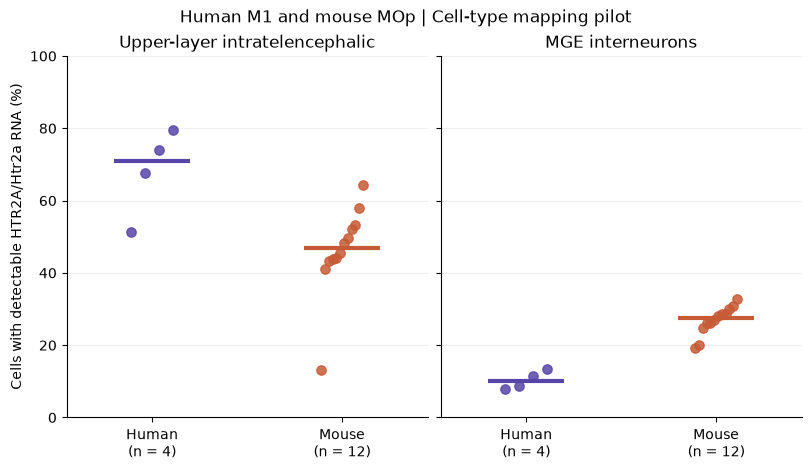

In [52]:
plot_data = supercluster_detection.reset_index()
panels = {
    "Upper-layer intratelencephalic": "Upper-layer intratelencephalic",
    "MGE interneuron": "MGE interneurons",
}
colors = {"Human": "#5745A8", "Mouse": "#C65B35"}

fig, axes = plt.subplots(1, 2, figsize=(8, 4.6), sharey=True, layout="constrained")

for ax, (supercluster, title) in zip(axes, panels.items()):
    group = plot_data.loc[plot_data["supercluster"].eq(supercluster)]
    xlabels = []

    for x, species in enumerate(["Human", "Mouse"]):
        rates = (
            group.loc[group["species"].eq(species), "pct_detected"]
            .dropna()
            .sort_values()
        )
        jitter = np.linspace(-0.11, 0.11, len(rates)) if len(rates) > 1 else 0

        ax.scatter(x + jitter, rates, color=colors[species], s=45, alpha=0.85)
        if len(rates):
            ax.hlines(rates.median(), x - 0.20, x + 0.20,
                      color=colors[species], linewidth=3)
        xlabels.append(f"{species}\n(n = {len(rates)})")

    ax.set_title(title)
    ax.set_xticks([0, 1], xlabels)
    ax.set(xlim=(-0.45, 1.45), ylim=(0, 100))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Cells with detectable HTR2A/Htr2a RNA (%)")
fig.suptitle("Human M1 and mouse MOp | Cell-type mapping pilot")
plt.show()